In [3]:
import pandas as pd

df = pd.read_csv("sales.csv")

print(df.head())
print(df.info())

   Month  Sales
0      1  12000
1      2  13500
2      3  14200
3      4  15000
4      5  16500
<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Month   24 non-null     int64
 1   Sales   24 non-null     int64
dtypes: int64(2)
memory usage: 516.0 bytes
None


In [5]:

import matplotlib.pyplot as plt

print("Matplotlib Imported Successfully!")


Matplotlib Imported Successfully!


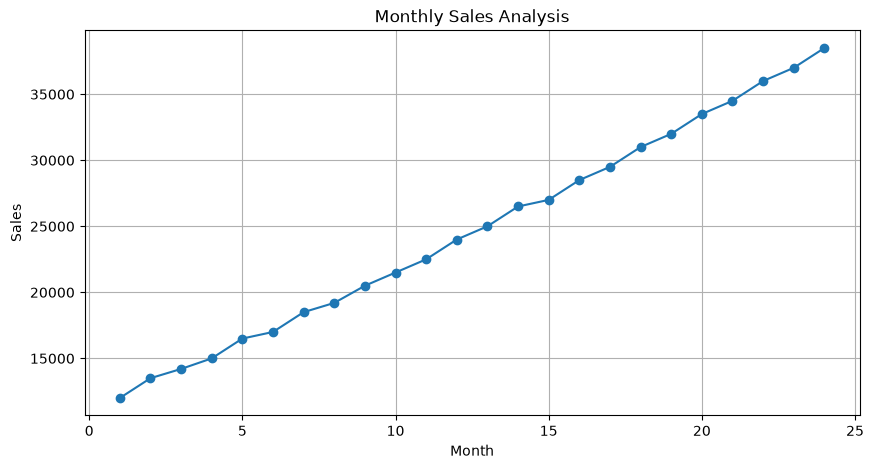

In [6]:

plt.figure(figsize=(10,5))

plt.plot(df['Month'], df['Sales'], marker='o')

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid(True)

plt.show()


In [14]:

import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.read_csv("sales.csv")

X = df[['Month']]
y = df['Sales']

model = LinearRegression()
model.fit(X, y)

print("Linear Regression Model Trained Successfully!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)


Linear Regression Model Trained Successfully!
Slope: 1141.4782608695652
Intercept: 10456.521739130434


In [15]:

future_months = pd.DataFrame({
    'Month': range(25, 31)
})

predictions = model.predict(future_months)

print("Future Sales Prediction:")

for month, sale in zip(future_months['Month'], predictions):
    print(f"Month {month}: {sale:.2f}")


Future Sales Prediction:
Month 25: 38993.48
Month 26: 40134.96
Month 27: 41276.43
Month 28: 42417.91
Month 29: 43559.39
Month 30: 44700.87


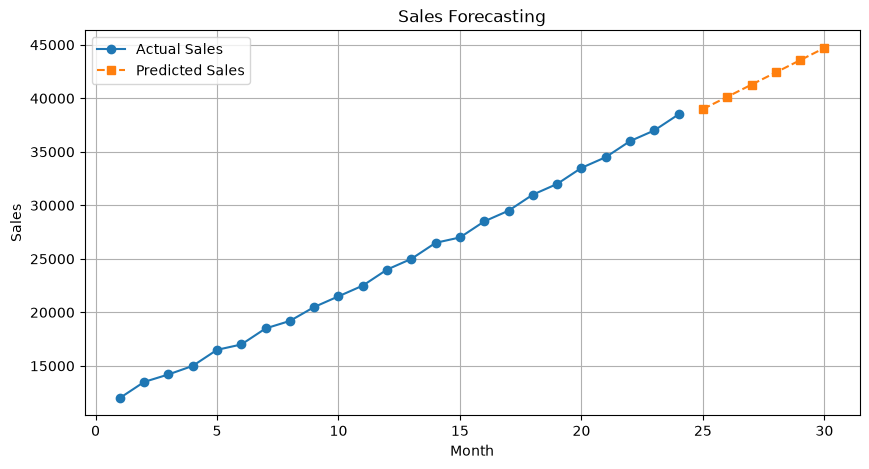

In [16]:

plt.figure(figsize=(10,5))

plt.plot(df['Month'], df['Sales'],
         marker='o', label='Actual Sales')

plt.plot(future_months['Month'], predictions,
         marker='s', linestyle='--',
         label='Predicted Sales')

plt.title('Sales Forecasting')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)

plt.show()


In [17]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

actual = df['Sales']
predicted = model.predict(df[['Month']])

mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predicted)

print("MODEL EVALUATION")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MODEL EVALUATION
------------------------
MAE: 299.02898550724643
MSE: 126936.95652173912
RMSE: 356.28213051139556
R2 Score: 0.9979709903617322


In [18]:

forecast_result = pd.DataFrame({
    'Month': future_months['Month'],
    'Predicted_Sales': predictions
})

forecast_result.to_csv(
    'forecasted_sales.csv',
    index=False
)

print("Forecast CSV File Saved Successfully!")
print(forecast_result)


Forecast CSV File Saved Successfully!
   Month  Predicted_Sales
0     25     38993.478261
1     26     40134.956522
2     27     41276.434783
3     28     42417.913043
4     29     43559.391304
5     30     44700.869565
